# Parameter-Efficient Fine-Tuning (PEFT) and LoRA

Full fine-tuning updates every weight of a pretrained model. For GPT-2 small that was manageable. For a 7-billion-parameter model it means more than 100 GB of training state, and a separate full copy of the model for every task. **Parameter-efficient fine-tuning (PEFT)** freezes the pretrained weights and trains a small number of new parameters instead. This notebook explains the most widely used PEFT method, **LoRA (Low-Rank Adaptation)**: why a small update can be enough, how it works, how to implement it, and what it does and does not save.

**What you will learn**

1. What full fine-tuning costs in memory and storage, and where that cost comes from.
2. How the main PEFT families differ in **what they train**.
3. Why a weight **update** may need far fewer degrees of freedom than the weight itself.
4. How LoRA writes the update as a product of two thin matrices, and why one of them starts at zero.
5. How to implement LoRA from scratch, check it, merge it into the weights, and swap adapters between tasks.
6. What LoRA costs and saves for real models (Qwen2.5 0.5B–7B), and how the Hugging Face `peft` library does the same thing.

**Prerequisites:** [Fine-tuning GPT-2](../fine_tuning/gpt2_fine_tuning.ipynb) (training-state memory, the training loop) · [Fine-tuning with the `Trainer`](../fine_tuning/hf_trainer_fine_tuning.ipynb) · [attention mechanisms](../../../module2/transformers/attention_mechanisms.ipynb) (Q/K/V projections and grouped-query attention). Matrix rank and the singular value decomposition (SVD) are refreshed in Section 3. For fp32, fp16, and bf16, and why training keeps an fp32 copy of the weights, see [Number formats for neural networks](floating_point_formats.ipynb).

**Setup:** Sections 1–8 use PyTorch and matplotlib only and run on a CPU in under a minute. Section 9 is **optional**: it downloads **Qwen2.5-0.5B-Instruct** (about 1 GB, Apache-2.0) and needs a GPU (Kaggle **T4**) and internet. It is switched off by default.

In [18]:
import copy
import io
import math
import os

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import FancyBboxPatch, Polygon, Circle

torch.manual_seed(42)
GB = 1e9                                # decimal gigabytes, as GPU memory is advertised
FROZEN, TRAINABLE = "#d5d8dc", "#f5b041"
print("PyTorch", torch.__version__)


def box(ax, x, y, w, h, label, color, fontsize=8.5):
    """A rounded box centred at (x, y)."""
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02", fc=color, ec="#333", lw=1))
    ax.text(x, y, label, ha="center", va="center", fontsize=fontsize)


def arrow(ax, start, end, color="#555"):
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color=color, lw=1.2))

PyTorch 2.10.0+cu128


## 1. What full fine-tuning costs

During training, every **trainable** parameter needs more than its own value in memory. With the usual mixed-precision AdamW setup:

| Item | Bytes per parameter | Why it is needed |
| --- | ---: | --- |
| Weight (fp16/bf16) | 2 | used in the forward and backward pass |
| Gradient (fp16/bf16) | 2 | result of the backward pass |
| fp32 master copy of the weight | 4 | small updates would be lost if added to a 16-bit weight |
| Adam first moment *m* (fp32) | 4 | running average of gradients |
| Adam second moment *v* (fp32) | 4 | running average of squared gradients |
| **Total** | **16** | the standard accounting used, for example, in the ZeRO paper (Rajbhandari et al., 2020) |

The GPT-2 notebook trained in fp32 (4 + 4 + 8 bytes), which also comes to 16 bytes per parameter. **Activations** (the intermediate values stored for the backward pass) come on top. They depend on batch size and sequence length, and are not counted here.

We use the **Qwen2.5** family, which the lab also uses. The architecture numbers come from each model's `config.json` on the Hugging Face Hub. The function below counts every weight from those numbers, so that we can reuse it for LoRA in Section 8.

In [19]:
QWEN = {   # from Qwen/Qwen2.5-*-Instruct config.json on the Hugging Face Hub
    "Qwen2.5-0.5B": dict(d=896,  layers=24, heads=14, kv_heads=2, ff=4864,  vocab=151936, tied=True),
    "Qwen2.5-1.5B": dict(d=1536, layers=28, heads=12, kv_heads=2, ff=8960,  vocab=151936, tied=True),
    "Qwen2.5-7B":   dict(d=3584, layers=28, heads=28, kv_heads=4, ff=18944, vocab=152064, tied=False),
}


def linear_shapes(c):
    """(in_features, out_features) of each weight matrix in one decoder layer."""
    d, kv = c["d"], c["kv_heads"] * (c["d"] // c["heads"])     # grouped-query attention: K and V are narrower
    return {"q_proj": (d, d), "k_proj": (d, kv), "v_proj": (d, kv), "o_proj": (d, d),
            "gate_proj": (d, c["ff"]), "up_proj": (d, c["ff"]), "down_proj": (c["ff"], d)}


def total_params(c):
    shapes = linear_shapes(c)
    per_layer = sum(i * o for i, o in shapes.values())
    per_layer += sum(shapes[m][1] for m in ("q_proj", "k_proj", "v_proj"))   # Qwen2 has biases on q, k, v only
    per_layer += 2 * c["d"]                                                    # two RMSNorm weight vectors
    embeddings = c["vocab"] * c["d"] * (1 if c["tied"] else 2)                 # 7B has a separate output head
    return embeddings + c["layers"] * per_layer + c["d"]                       # + final norm


print(f"{'model':<14}{'parameters':>16}{'weights (16-bit)':>19}{'full fine-tuning state':>25}")
for name, c in QWEN.items():
    n = total_params(c)
    print(f"{name:<14}{n:>16,}{2 * n / GB:>16.1f} GB{16 * n / GB:>22.1f} GB")

model               parameters   weights (16-bit)   full fine-tuning state
Qwen2.5-0.5B       494,032,768             1.0 GB                   7.9 GB
Qwen2.5-1.5B     1,543,714,304             3.1 GB                  24.7 GB
Qwen2.5-7B       7,615,616,512            15.2 GB                 121.8 GB


The counts match the model cards (0.49B, 1.54B, and 7.61B parameters), which confirms the formula.

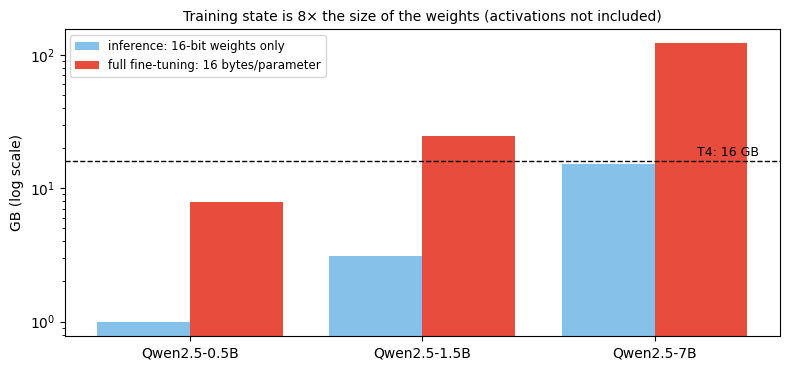

In [20]:
names = list(QWEN)
weights_gb = [2 * total_params(QWEN[n]) / GB for n in names]
full_gb = [16 * total_params(QWEN[n]) / GB for n in names]

fig, ax = plt.subplots(figsize=(8, 3.8))
xs = torch.arange(len(names)).float()
ax.bar(xs - 0.2, weights_gb, 0.4, label="inference: 16-bit weights only", color="#85c1e9")
ax.bar(xs + 0.2, full_gb, 0.4, label="full fine-tuning: 16 bytes/parameter", color="#e74c3c")
ax.axhline(16, color="k", ls="--", lw=1); ax.text(2.45, 17.5, "T4: 16 GB", ha="right", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("GB (log scale)"); ax.set_xticks(xs); ax.set_xticklabels(names)
ax.set_title("Training state is 8× the size of the weights (activations not included)", fontsize=10)
ax.legend(fontsize=8.5, loc="upper left"); plt.tight_layout(); plt.show()

**Reading the figure**

- Fully fine-tuning Qwen2.5-0.5B needs about 8 GB before activations, which fits on a T4. The 1.5B model needs about 25 GB, and the 7B model more than 120 GB. Both are beyond a free GPU.
- Running the 7B model for **inference** needs about 15 GB, which almost fits. Training is the problem, not using the model.
- **Storage** is a second cost. Fine-tuning a 7B model for 10 tasks produces 10 separate 15 GB checkpoints, although most of their weights hardly change.

> Can we freeze the pretrained weights, which then need no gradients, master copies, or optimizer state, and train only a **small** set of new parameters?

## 2. The PEFT family: what gets trained

All PEFT methods freeze the pretrained weights. They differ in **which** new or existing parameters they train, and that decides what they cost at inference.

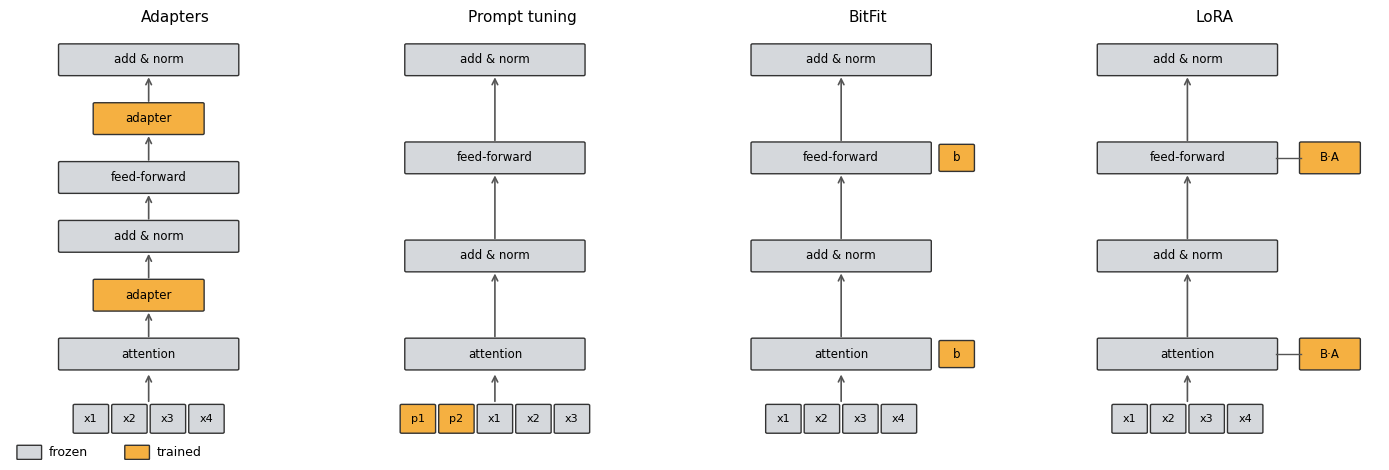

In [21]:
def draw_peft_family():
    panels = {
        "Adapters":      ["attention", "adapter", "add & norm", "feed-forward", "adapter", "add & norm"],
        "Prompt tuning": ["attention", "add & norm", "feed-forward", "add & norm"],
        "BitFit":        ["attention", "add & norm", "feed-forward", "add & norm"],
        "LoRA":          ["attention", "add & norm", "feed-forward", "add & norm"],
    }
    fig, axes = plt.subplots(1, 4, figsize=(14, 4.8))
    for ax, (name, rows) in zip(axes, panels.items()):
        ax.set_xlim(0, 4.3); ax.set_ylim(-0.7, 6.6); ax.axis("off"); ax.set_title(name, fontsize=11)
        if name == "Prompt tuning":       # trainable "virtual tokens" in front of the real ones
            tokens = [("p1", TRAINABLE), ("p2", TRAINABLE), ("x1", FROZEN), ("x2", FROZEN), ("x3", FROZEN)]
        else:
            tokens = [(f"x{i}", FROZEN) for i in range(1, 5)]
        start = 1.8 - 0.25 * (len(tokens) - 1)
        for i, (label, color) in enumerate(tokens):
            box(ax, start + 0.5 * i, 0, 0.42, 0.45, label, color, 8)
        ys = [1.1 + i * (5.0 / (len(rows) - 1)) for i in range(len(rows))] if len(rows) > 1 else [3]
        arrow(ax, (1.8, 0.25), (1.8, ys[0] - 0.3))
        for k, (y, row) in enumerate(zip(ys, rows)):
            color = TRAINABLE if row == "adapter" else FROZEN
            box(ax, 1.8, y, 2.3 if row != "adapter" else 1.4, 0.5, row, color)
            if k > 0:
                arrow(ax, (1.8, ys[k - 1] + 0.25), (1.8, y - 0.25))
            if row in ("attention", "feed-forward"):
                if name == "LoRA":
                    box(ax, 3.65, y, 0.75, 0.5, "B·A", TRAINABLE)
                    ax.plot([2.95, 3.27], [y, y], color="#555", lw=1)
                if name == "BitFit":
                    box(ax, 3.3, y, 0.42, 0.42, "b", TRAINABLE)
    axes[0].add_patch(FancyBboxPatch((0.1, -0.68), 0.3, 0.22, boxstyle="round,pad=0.01", fc=FROZEN, ec="#333"))
    axes[0].text(0.5, -0.57, "frozen", va="center", fontsize=9)
    axes[0].add_patch(FancyBboxPatch((1.5, -0.68), 0.3, 0.22, boxstyle="round,pad=0.01", fc=TRAINABLE, ec="#333"))
    axes[0].text(1.9, -0.57, "trained", va="center", fontsize=9)
    plt.tight_layout(); plt.show()


draw_peft_family()

**Reading the figure:** each panel shows one Transformer block. Grey parts are frozen, orange parts are trained.

| Method | What is trained | Cost at inference | Limitation |
| --- | --- | --- | --- |
| **Adapters** (Houlsby et al., 2019) | small bottleneck MLPs inserted after sublayers | extra layers run in sequence, so slightly slower | added latency, especially at small batch sizes |
| **Prompt tuning** (Lester et al., 2021); **prefix tuning** (Li & Liang, 2021) | learned vectors placed in front of the input, or in front of the keys and values in every layer | sequence becomes longer | uses part of the context window; harder to optimize on smaller models |
| **BitFit** (Ben Zaken et al., 2021) | only the bias terms | none | many recent LLMs have few or no biases (Qwen2.5 only on Q/K/V; Llama none) |
| **LoRA** (Hu et al., 2021) | a low-rank update to chosen weight matrices | **none after merging** (Section 7) | the update to each matrix is limited to rank `r` |

LoRA is the default choice in practice, and the rest of this notebook is about it.

## 3. Why a small update can be enough

### Refresher: rank and the SVD

- The **rank** of a matrix is the number of independent directions it can produce. A `d × k` matrix has rank at most `min(d, k)`.
- The **singular value decomposition** writes any matrix as `M = U Σ Vᵀ`. The singular values σ₁ ≥ σ₂ ≥ … in `Σ` measure how much each direction contributes. Keeping the top `r` of them gives the **best rank-`r` approximation** of `M`. The fraction of "energy" it keeps is `(σ₁² + … + σᵣ²) / Σ σᵢ²`.

### The hypothesis

A pretrained weight matrix is usually high-rank: it encodes a great deal. But fine-tuning starts from a model that already knows the language, and only **adjusts** it for a new task. Aghajanyan et al. (2020) found that fine-tuning can work in a surprisingly small random subspace: about 200 trainable parameters, projected into RoBERTa's full parameter space, reached 90% of full fine-tuning performance on one paraphrase task (MRPC). Hu et al. (2021) drew the hypothesis behind LoRA from that result: **the change ΔW = W_fine-tuned − W_pretrained has a low "intrinsic rank"**.

### A toy check

We build a setting we can train in seconds:

- **Task A**, the "pretraining" task: a small random network (the *teacher*) maps 16 inputs to 4 outputs. A larger student MLP learns it from 4,000 examples.
- **Task B**, the "fine-tuning" task: a *related* teacher, made by adding random noise to every weight of teacher A (30% of each weight's scale, so the change is full-rank). The student gets only **256** examples, as is typical for fine-tuning.

We fully fine-tune the student on task B and look at the singular values of the change to its middle 128 × 128 weight matrix. This is an **illustration**, not evidence about LLMs. That evidence comes from the papers above.

**How we score a model: nMSE.** The cells below report the **normalized mean squared error**, `nMSE = MSE / Var(y)`: the mean squared error divided by the variance of the targets. Dividing by the variance removes the scale of the outputs, so scores on different tasks can be compared. **0** is perfect, and **1** is what you get by always predicting the average target, so lower is better. Equivalently, `nMSE = 1 − R²`: an nMSE of 0.12 means the model leaves 12% of the targets' variance unexplained.

In [ ]:
D_IN, HID, D_OUT = 16, 128, 4
FT_STEPS = 300


def make_teacher(base=None, noise=0.3, seed=0):
    torch.manual_seed(seed)
    t = nn.Sequential(nn.Linear(D_IN, 32), nn.Tanh(), nn.Linear(32, D_OUT))
    if base is not None:                              # a related task: perturb every weight of the base teacher
        t.load_state_dict(base.state_dict())
        with torch.no_grad():
            for p in t.parameters():
                p.add_(noise * p.std() * torch.randn_like(p))
    return t


def make_data(teacher, n, seed):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, D_IN, generator=g)
    with torch.no_grad():
        return x, teacher(x)


def mlp(seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Linear(D_IN, HID), 
        nn.GELU(), 
        nn.Linear(HID, HID), 
        nn.GELU(), 
        nn.Linear(HID, D_OUT)
    )


def train(model, x, y, steps, lr, batch=64):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    g = torch.Generator().manual_seed(0)               # same batch order for every run
    for _ in range(steps):
        idx = torch.randint(0, len(x), (batch,), generator=g)
        loss = F.mse_loss(model(x[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return model


@torch.no_grad()
def nmse(model, x, y):
    """MSE divided by the target variance: 0 is perfect, 1 is no better than predicting the mean."""
    return (F.mse_loss(model(x), y) / y.var()).item()


teacher_A = make_teacher(seed=0)
teacher_B = make_teacher(base=teacher_A, seed=1)
xA, yA = make_data(teacher_A, 4000, seed=10); xAv, yAv = make_data(teacher_A, 1000, seed=11)
xB, yB = make_data(teacher_B, 256, seed=20);  xBv, yBv = make_data(teacher_B, 1000, seed=21)

base = train(mlp(), xA, yA, steps=3000, lr=1e-3)       # the "pretrained" model
print(f"pretrained model  | task A val nMSE {nmse(base, xAv, yAv):.3f} | task B val nMSE {nmse(base, xBv, yBv):.3f}")

full = train(copy.deepcopy(base), xB, yB, steps=FT_STEPS, lr=1e-3)
print(f"full fine-tuning  | task B val nMSE {nmse(full, xBv, yBv):.3f}")

pretrained model  | task A val nMSE 0.002 | task B val nMSE 0.122
full fine-tuning  | task B val nMSE 0.008


ΔW from fine-tuning        energy in top 4: 39% | top 8: 55% | top 16: 74%
random matrix, same norm   energy in top 4: 12% | top 8: 22% | top 16: 38%


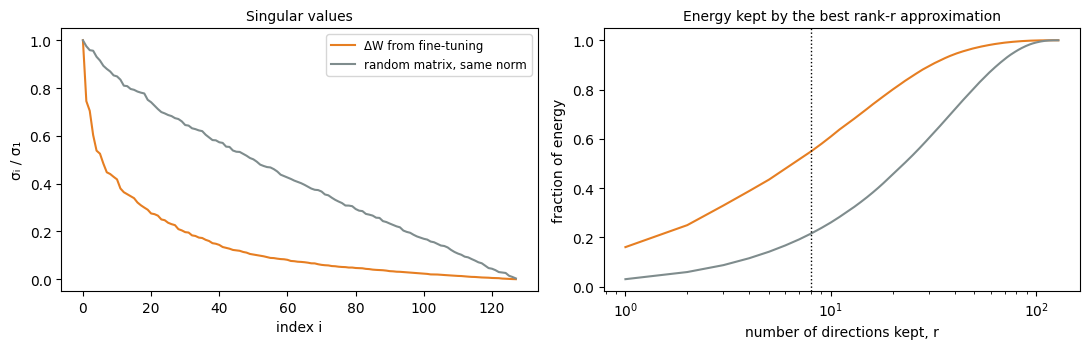

In [23]:
delta = (full[2].weight - base[2].weight).detach()                  # change to the middle 128 x 128 matrix
torch.manual_seed(0)
random_same_norm = torch.randn_like(delta) * delta.norm() / delta.numel() ** 0.5

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for M, label, color in [(delta, "ΔW from fine-tuning", "#e67e22"), (random_same_norm, "random matrix, same norm", "#7f8c8d")]:
    s = torch.linalg.svdvals(M)
    ax1.plot(s / s[0], label=label, color=color)
    energy = (s ** 2).cumsum(0) / (s ** 2).sum()
    ax2.plot(range(1, len(s) + 1), energy, label=label, color=color)
    print(f"{label:<26} energy in top 4: {energy[3]:.0%} | top 8: {energy[7]:.0%} | top 16: {energy[15]:.0%}")
ax1.set_xlabel("index i"); ax1.set_ylabel("σᵢ / σ₁"); ax1.set_title("Singular values", fontsize=10); ax1.legend(fontsize=8.5)
ax2.set_xlabel("number of directions kept, r"); ax2.set_ylabel("fraction of energy"); ax2.set_xscale("log")
ax2.set_title("Energy kept by the best rank-r approximation", fontsize=10); ax2.axvline(8, color="k", ls=":", lw=1)
plt.tight_layout(); plt.show()

**Reading the figure**

- **Left:** the singular values of a random matrix fall off slowly, because no direction is special. Those of ΔW drop steeply at first: a few directions carry most of the change.
- **Right:** in our run, the top 8 directions held 55% of ΔW's energy, compared with 22% for a random matrix of the same size and norm (top 16: 74% vs. 38%).
- ΔW is **approximately**, not exactly, low-rank: 8 directions still miss almost half of its energy. Section 6 shows why that matters less than it seems. LoRA does not have to copy the ΔW that full fine-tuning found; it only has to find *some* low-rank change that solves the task.
- In this toy, the change we built into the task was full-rank (noise on every teacher weight). Any concentration in ΔW therefore comes from fine-tuning itself: only a few hundred steps of gradients, from limited data, starting from a model that already solves a related task.
- LoRA turns this observation into a design: **if ΔW is approximately low-rank, train a low-rank ΔW directly.**

**The grey baseline: what "same norm" means.** The random matrix is built to be the same overall size as ΔW, so the two differ only in how that size is spread across directions. Size here is the **Frobenius norm**, ‖M‖_F = √(Σᵢⱼ Mᵢⱼ²): square every entry, add them up, and take the square root. It is the ordinary length of the matrix, treated as one long vector of entries. For example, M = [[1, 2], [2, 4]] has ‖M‖_F = √(1 + 4 + 4 + 16) = 5.

- **The squared norm is the total energy.** It also equals the sum of the squared singular values: ‖M‖_F² = σ₁² + σ₂² + …. In the example, the second row is twice the first, so M has rank 1: σ₁ = 5, σ₂ = 0, and 5² = 25. This is the "energy" from the refresher above. The right panel shows what fraction of ‖ΔW‖_F² the top `r` directions hold.
- **What the comparison shows.** With the same total energy, the two curves differ only in how that energy is distributed: concentrated in a few directions for ΔW, spread across all 128 for the random matrix. Both panels are normalized (σᵢ / σ₁ and energy fractions), so the overall scale would cancel anyway. Matching the norms makes the comparison like-for-like; what the baseline really supplies is a matrix of the same size with no preferred direction.

#### Why task B is "teacher A plus random noise"

The fine-tuning task needs three properties, and perturbing every weight of teacher A gives all three.

1. **It must be related to task A.** Fine-tuning only makes sense when the pretrained model already knows something useful. Teacher B starts as an exact copy of teacher A and is then nudged. In our run the pretrained model already reached nMSE 0.122 on task B before any fine-tuning, well below the 1.0 of predicting the mean: it half knows the task, as a pretrained LLM half knows a new one. A teacher with fresh random weights would be an unrelated task, so training on it would be learning from scratch, not fine-tuning.
2. **How related it is can be controlled.** `noise=0.3` moves each weight by 30% of its typical size. Near 0, task B is almost task A and there is little to learn. Very large noise makes the tasks effectively unrelated. 0.3 sits in between.
3. **Low rank must not be built in.** The question is whether ΔW *turns out* low-rank. If task B were made with a low-rank change, a low-rank ΔW would prove nothing: we would be reading back what we put in. Independent noise on every weight is **full-rank**, with no preferred direction, so the setup is tilted *against* finding low-rank structure. The structure that does appear must come from fine-tuning itself.

| How task B could be built | Problem |
| --- | --- |
| a fresh random teacher | unrelated task: training from scratch, not fine-tuning |
| a low-rank change to teacher A | circular: the low-rank result would be built in |
| a change to only one teacher weight or layer | too narrow, and it also builds in structure |
| **noise on every weight of teacher A** | related, adjustable, and no low-rank structure planted |

Two further points:

- The noise is added to the **teacher** (16 → 32 → 4), but ΔW is measured in the **student**'s middle 128 × 128 matrix, which has no counterpart in the teacher. The shape of ΔW is not copied from the noise: the student had to find its own weight change to imitate the new teacher.
- Real fine-tuning tasks are not random perturbations. A new output format, domain, or instruction style is a structured change, possibly *more* low-rank than random noise. That is why this toy is an illustration under a deliberately unfavorable setup, not evidence about LLMs.

## 4. LoRA: a low-rank update next to a frozen weight

For a linear layer `h = W₀x`, with `W₀` of size `d × k` (output × input, as stored by `nn.Linear`), LoRA keeps `W₀` frozen and adds a trainable update in factored form:

$$h = W_0 x + \Delta W x = W_0 x + \frac{\alpha}{r}\, B A x, \qquad A \in \mathbb{R}^{r \times k},\; B \in \mathbb{R}^{d \times r},\; r \ll \min(d, k)$$

| Symbol | Meaning | Set by |
| --- | --- | --- |
| `k` | **input** width of the matrix: how many features go into it | the model's architecture |
| `d` | **output** width of the matrix: how many features come out | the model's architecture |
| `r` | **rank** of the update: the narrow middle width that `x` is squeezed through | you, as a hyperparameter (`LoraConfig(r=8)` in `peft`) |
| `α` | **scaling constant** (alpha): the update `BAx` is multiplied by `α / r` before it is added to `W₀x`. It is fixed, not trained (see "The scaling factor α / r" below) | you, as a hyperparameter (`LoraConfig(lora_alpha=16)` in `peft`) |

So `A` maps `k → r` features and `B` maps `r → d`. Their product `BA` is `d × k`, the same shape as `W₀`, so the two can be added. `k` and `d` change from matrix to matrix; `r` is usually the same for every adapted matrix. These letters describe one weight matrix: `k` has nothing to do with attention's keys, and `d` equals the model width only for some matrices.

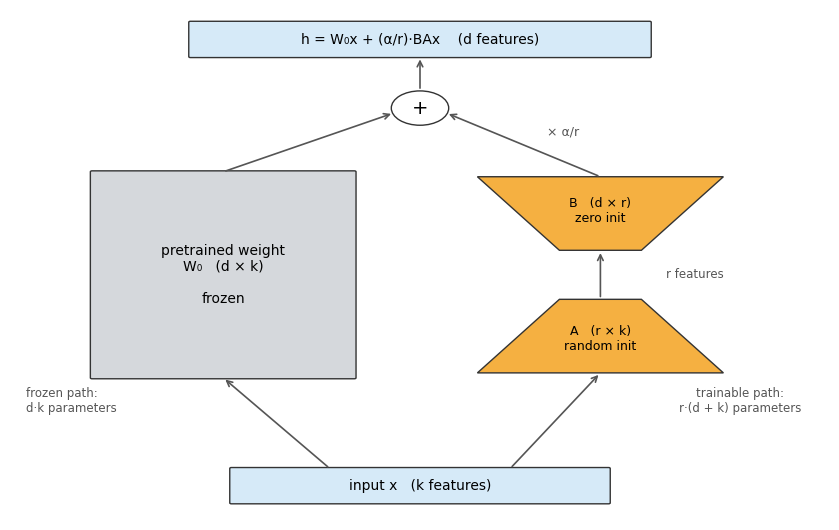

In [24]:
def draw_lora():
    fig, ax = plt.subplots(figsize=(8.5, 5.4))
    ax.set_xlim(0, 10); ax.set_ylim(0, 10.4); ax.axis("off")
    box(ax, 5, 0.7, 4.6, 0.7, "input x   (k features)", "#d6eaf8", 10)
    box(ax, 2.6, 5.0, 3.2, 4.2, "pretrained weight\nW₀   (d × k)\n\nfrozen", FROZEN, 10)
    ax.add_patch(Polygon([[5.7, 3.0], [8.7, 3.0], [7.7, 4.5], [6.7, 4.5]], fc=TRAINABLE, ec="#333"))   # A: k -> r
    ax.text(7.2, 3.7, "A   (r × k)\nrandom init", ha="center", va="center", fontsize=9)
    ax.text(8.0, 5.0, "r features", ha="left", va="center", fontsize=8.5, color="#555")
    ax.add_patch(Polygon([[6.7, 5.5], [7.7, 5.5], [8.7, 7.0], [5.7, 7.0]], fc=TRAINABLE, ec="#333"))   # B: r -> d
    ax.text(7.2, 6.3, "B   (d × r)\nzero init", ha="center", va="center", fontsize=9)
    ax.add_patch(Circle((5, 8.4), 0.35, fc="white", ec="#333")); ax.text(5, 8.4, "+", ha="center", va="center", fontsize=14)
    box(ax, 5, 9.8, 5.6, 0.7, "h = W₀x + (α/r)·BAx    (d features)", "#d6eaf8", 10)
    arrow(ax, (3.9, 1.05), (2.6, 2.9)); arrow(ax, (6.1, 1.05), (7.2, 3.0))
    arrow(ax, (7.2, 4.5), (7.2, 5.5))
    arrow(ax, (2.6, 7.1), (4.68, 8.3)); arrow(ax, (7.2, 7.0), (5.32, 8.3))
    ax.text(6.55, 7.85, "× α/r", fontsize=9, color="#555")
    arrow(ax, (5, 8.75), (5, 9.45))
    ax.text(0.2, 2.2, "frozen path:\nd·k parameters", fontsize=8.5, color="#555")
    ax.text(8.9, 2.2, "trainable path:\nr·(d + k) parameters", fontsize=8.5, color="#555", ha="center")
    plt.tight_layout(); plt.show()


draw_lora()

**Reading the figure**

- The input goes through two paths in parallel. The **frozen** path is the original layer. The **trainable** path first **compresses** `x` from `k` to `r` features with `A`, then **expands** it back to `d` features with `B`.
- Because `x` is squeezed through `r` features, the update `BA` has rank at most `r`, whatever `A` and `B` learn.
- **Parameter count:** the frozen path has `d · k` weights; the trainable path has `r · (d + k)`. For Qwen2.5-0.5B's `q_proj` (896 × 896) with `r = 8`, that is 14,336 trainable parameters instead of 802,816 (1.8%).

**Shape trace** for a batch of `N` sequences of `T` tokens:

| Step | Shape |
| --- | --- |
| `x` | `(N, T, k)` |
| `x @ A.T` | `(N, T, r)` |
| `(x @ A.T) @ B.T` | `(N, T, d)`, the same shape as `W₀x`, so the two can be added |

### Initialization: why `B` starts at zero

`A` starts random and `B` starts at **zero**, so `BA = 0` and the model at step 0 is exactly the pretrained model. Fine-tuning starts from what the model already knows instead of from a randomly disturbed version of it.

### The scaling factor α / r

`α` (alpha) is a constant that you choose, like `r`; it is not trained. The adapter's output `BAx` is multiplied by `α / r` before it is added to `W₀x`, so `α / r` sets how strongly the adapter can push the layer away from its pretrained behaviour. In `peft` it is `LoraConfig(lora_alpha=...)`; in Section 5 it is the `alpha` argument of `LoRALinear`, stored once as `self.scale = alpha / r`. For example, `r = 8` with `α = 16` gives a scale of `16 / 8 = 2`.

### Which matrices get an adapter

LoRA does not factor `W₀` itself. `W₀` stays full-size and frozen; only the **update** `ΔW` is written as `BA`. In a transformer you choose which weight matrices receive such an update (in `peft`, with the `target_modules` option). Each chosen matrix gets **its own** pair `A`, `B`, shaped by that matrix: `A` takes the matrix's input width `k` down to `r`, and `B` takes `r` back up to its output width `d`. Nothing is shared between matrices or between layers.

**Qwen2.5-0.5B** (Llama-style: 24 layers, model width 896), with `r = 8`. Per matrix, in one layer:

| Block | Module | `W₀`: in → out (`k → d`) | `A` (`r × k`) | `B` (`d × r`) | `W₀` parameters, `d·k` | LoRA parameters, `r·(d + k)` | LoRA / `W₀` |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Attention | `q_proj` | 896 → 896 | 8 × 896 | 896 × 8 | 802,816 | 14,336 | 1.79% |
| | `k_proj` | 896 → 128 | 8 × 896 | 128 × 8 | 114,688 | 8,192 | 7.14% |
| | `v_proj` | 896 → 128 | 8 × 896 | 128 × 8 | 114,688 | 8,192 | 7.14% |
| | `o_proj` | 896 → 896 | 8 × 896 | 896 × 8 | 802,816 | 14,336 | 1.79% |
| Feed-forward | `gate_proj` | 896 → 4864 | 8 × 896 | 4864 × 8 | 4,358,144 | 46,080 | 1.06% |
| | `up_proj` | 896 → 4864 | 8 × 896 | 4864 × 8 | 4,358,144 | 46,080 | 1.06% |
| | `down_proj` | 4864 → 896 | 8 × 4864 | 896 × 8 | 4,358,144 | 46,080 | 1.06% |

Whole model, all 24 layers:

| What is trained | Parameters | Share of the model |
| --- | --- | --- |
| Full fine-tuning: every parameter | 494,032,768 | 100% |
| (of which the seven matrices above, in all 24 layers) | 357,826,560 | 72.4% |
| LoRA on `q_proj`, `v_proj` | 540,672 | 0.11% |
| LoRA on all seven matrices | 4,399,104 | 0.89% |

- `k_proj` and `v_proj` are narrower than `q_proj` because of grouped-query attention: the 14 query heads share 2 key/value heads of 64 features each, so 2 × 64 = 128.
- The feed-forward block is SwiGLU, which uses three matrices: `down_proj(SiLU(gate_proj·x) ⊙ up_proj·x)`.
- The LoRA share is largest for the narrow `k_proj` and `v_proj` (7%): `r·(d + k)` shrinks more slowly than `d·k` when one side is small. For large square-ish matrices it is around 1–2%.
- The other 27.6% of the model is almost entirely the token embedding table (151,936 × 896), which LoRA leaves untouched.
- 540,672 is the number `peft` reports in Section 9 (0.1093%).

**GPT-2 small** (12 layers, model width 768, 12 heads), with `r = 8`. Per matrix, in one layer:

| Block | Module | `W₀`: in → out (`k → d`) | `A` (`r × k`) | `B` (`d × r`) | `W₀` parameters, `d·k` | LoRA parameters, `r·(d + k)` | LoRA / `W₀` |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Attention | `attn.c_attn` | 768 → 2304 (q, k, v fused) | 8 × 768 | 2304 × 8 | 1,769,472 | 24,576 | 1.39% |
| | `attn.c_proj` | 768 → 768 | 8 × 768 | 768 × 8 | 589,824 | 12,288 | 2.08% |
| Feed-forward | `mlp.c_fc` | 768 → 3072 | 8 × 768 | 3072 × 8 | 2,359,296 | 30,720 | 1.30% |
| | `mlp.c_proj` | 3072 → 768 | 8 × 3072 | 768 × 8 | 2,359,296 | 30,720 | 1.30% |

Whole model, all 12 layers:

| What is trained | Parameters | Share of the model |
| --- | --- | --- |
| Full fine-tuning: every parameter | 124,439,808 | 100% |
| (of which the four matrices above, in all 12 layers) | 84,934,656 | 68.3% |
| LoRA on `c_attn` | 294,912 | 0.24% |
| LoRA on all four matrices | 1,179,648 | 0.95% |

- **q, k and v are one matrix.** `c_attn` computes all three in one multiplication, and its 2304 outputs are split into thirds of 768. An adapter on `c_attn` therefore updates q, k and v together: the rows of `B` split into the same thirds, and the three updates share one `A`. With `peft` you cannot adapt q and v but leave k alone. (The LoRA paper's own GPT-2 code, `loralib`, could switch the k slice off.)
- There is no grouped-query attention, so k and v are full width (768 each).
- The feed-forward block is a plain GELU MLP with two matrices, `c_proj(GELU(c_fc·x))`, and no gate.
- **Two modules are called `c_proj`.** `peft` matches each entry of `target_modules` against the end of a module's name, so `"c_proj"` selects both `attn.c_proj` and `mlp.c_proj`. Write `"attn.c_proj"` to select only the attention one.
- GPT-2's layers are `Conv1D`, not `nn.Linear`. Despite the name, `Conv1D` is an ordinary linear layer whose weight is stored transposed, as `(k, d)`. `peft` handles this with the option `fan_in_fan_out=True`, which it sets for GPT-2 automatically, with a warning.
- Most of the remaining 31.7% is the token and position embeddings (50,257 × 768 and 1,024 × 768).

**In both models**, the embeddings, the normalization weights (RMSNorm or LayerNorm) and the biases get no adapter. To see a model's module names, print one layer: `print(model.model.layers[0])` for Qwen2.5, `print(model.transformer.h[0])` for GPT-2.

## 5. LoRA from scratch

`LoRALinear` wraps an existing `nn.Linear`. It freezes the wrapped layer, adds `A` and `B`, and can **merge** the update into the weight (Section 7).

In [ ]:
# A drop-in replacement for one nn.Linear layer: h = W0 x + (alpha/r) B A x
class LoRALinear(nn.Module):
    # base: the pretrained layer to wrap (holds W0 of shape (d, k)); r: rank; alpha: scaling numerator
    def __init__(self, base: nn.Linear, r: int, alpha: float):        
        super().__init__()
        # Keep the original layer inside the wrapper; its forward pass computes W0 x + b
        self.base = base
        # Loop over the wrapped layer's parameters: its weight W0 and its bias b (if any)
        for p in self.base.parameters():
            # Freeze each one: no gradients, so the optimizer never changes the pretrained weights
            p.requires_grad_(False)
        # The update is multiplied by alpha / r (Section 4); store the constant once
        self.scale = alpha / r
        # A has shape (r, k): it compresses the k input features to r. Values are filled in below
        self.A = nn.Parameter(torch.empty(r, base.in_features))
        # B has shape (d, r): it expands r features back to d. It starts at zero, so BA = 0 at the start
        self.B = nn.Parameter(torch.zeros(base.out_features, r))
        # Fill A with small random values: the same init nn.Linear uses for its weights (and peft's default for A)
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        # Remember whether BA has been added into W0 (see merge below); a new adapter is not merged
        self.merged = False

    # x has shape (..., k), e.g. (N, T, k); the output has shape (..., d)
    def forward(self, x):
        # Frozen path: the original layer, W0 x + b, shape (..., d)
        out = self.base(x)
        # If BA is already inside W0, the line above has already applied the update
        if not self.merged:
            # Trainable path: (..., k) -> x @ A.T -> (..., r) -> @ B.T -> (..., d), scaled and added on
            out = out + self.scale * (x @ self.A.T) @ self.B.T
        # Same shape as the original layer's output, so the wrapper can replace it anywhere
        return out

    # Merging edits the weights directly; it is not a training step, so autograd must not track it
    @torch.no_grad()
    # Fold the update into the frozen weight: W0 <- W0 + (alpha/r) B A
    def merge(self):
        # Guard against merging twice, which would add the update a second time
        if not self.merged:
            # B @ A is (d, r) @ (r, k) = (d, k), the same shape as W0, so it can be added in place
            self.base.weight += self.scale * self.B @ self.A
            # From now on, forward() skips the trainable path: one matrix multiply, as in the original layer
            self.merged = True

    # Undoing the merge also edits the weights directly, so again no autograd tracking
    @torch.no_grad()
    # Take the update back out: W0 <- W0 - (alpha/r) B A, recovering the pretrained weight
    def unmerge(self):
        # Only subtract if the update was added; otherwise W0 would be damaged
        if self.merged:
            # Subtract exactly what merge() added (up to floating-point rounding)
            self.base.weight -= self.scale * self.B @ self.A
            # forward() goes back to computing the two paths separately
            self.merged = False


def add_lora(model, r, alpha, targets=None):
    """Freeze the model and wrap every nn.Linear (or only those whose name is in targets) with LoRA."""
    # First freeze everything, including layers that will not get an adapter (embeddings, norms, ...)
    for p in model.parameters():
        p.requires_grad_(False)
    # Visit every module; list() takes a snapshot, so replacing children below does not disturb the loop
    for parent in list(model.modules()):
        # Look at each direct child by its attribute name, e.g. "q_proj" or "2"
        for name, child in list(parent.named_children()):
            # Wrap it if it is a linear layer and either no targets were given or its name is one of them
            if isinstance(child, nn.Linear) and (targets is None or name in targets):
                # Replace the child on its parent: parent.<name> is now the LoRA wrapper around the old layer
                setattr(parent, name, LoRALinear(child, r, alpha))
    # The model is changed in place; return it for convenience
    return model


def count_params(model):
    # Trainable: parameters that will receive gradients (after add_lora, only the A and B matrices)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    # Return (trainable, total); the total includes the frozen weights
    return trainable, sum(p.numel() for p in model.parameters())

### What `merge()` and `unmerge()` do

After training, the update can stay as a separate path next to `W₀`, or it can be folded into `W₀` itself. `merge()` and `unmerge()` move between these two forms.

**`merge()`** computes the full update once and adds it to the frozen weight:

$$W_0 \leftarrow W_0 + \frac{\alpha}{r}\, B A$$

1. `self.B @ self.A` multiplies `(d × r)` by `(r × k)` and gives a `d × k` matrix, the same shape as `W₀`. This is the only place the class builds `BA`. `forward()` never does, because building a `d × k` matrix on every call would cost as much as `W₀` itself.
2. The product is scaled by `α/r` and added to `self.base.weight` in place.
3. `self.merged = True` tells `forward()` to skip the `A`/`B` path. Without this flag, the update would be applied twice: once inside the weight and once through `A` and `B`.

**`unmerge()`** subtracts the same quantity, `W₀ ← W₀ − (α/r)·BA`, and sets `merged = False`. This gives back the pretrained weight, up to floating-point rounding.

Two details apply to both methods:

- They run under `@torch.no_grad()`. They edit the weights directly and are not training steps, so autograd must not record them.
- They check the flag first. This prevents merging twice, which would add the update twice, and unmerging a layer that was never merged, which would subtract an update that was never added.

**Why merging does not change the output.** Matrix multiplication distributes over addition:

$$\underbrace{W_0 x + \frac{\alpha}{r} B A x}_{\text{unmerged: two paths}} \;=\; \underbrace{\left(W_0 + \frac{\alpha}{r} B A\right) x}_{\text{merged: one matrix}}$$

The bias `b` of the wrapped layer is added once in both forms and is not changed. Section 7 checks this equality numerically.

**What the unmerged form costs.** For each adapted matrix, the unmerged layer does `r · (d + k)` extra multiply-adds per token, on top of the `d · k` for `W₀x`. For Qwen2.5-0.5B's `q_proj` with `r = 8`, that is 14,336 on top of 802,816, or about 1.8%. The arithmetic is small, but the path also adds separate operations: two thin matrix multiplies, a scaling, and an addition. Each one is a separate GPU kernel with its own memory reads and writes. During token-by-token generation with small batches, this overhead can matter more than the multiply-add count suggests. A merged layer is a single `nn.Linear` again, so it costs exactly what the original layer cost.

**Merged or unmerged inference?**

| Situation | Prefer | Why |
| --- | --- | --- |
| Deploying one fine-tuned model for one task | merged | Same architecture, parameter count, and speed as the original model. No LoRA code is needed at inference. |
| Serving several tasks from one base model | unmerged | One copy of the base stays in memory. Switching tasks means loading a different `A` and `B` (Section 7). |
| Comparing the adapted model with the base model | unmerged | The base weights stay clean, so the adapter can be switched off without reloading anything. |
| Training, or continuing to train | unmerged | A merged layer skips `A` and `B` in `forward()`, so they receive no gradients and stop learning. |
| Base model loaded in 4-bit (QLoRA) | unmerged, or merge into a 16-bit copy of the base | A 4-bit base plus a small adapter uses far less memory than a merged 16-bit model. Merging into the 4-bit weights loses part of the update to rounding ([next lecture](quantization_qlora.ipynb)). |
| Storing or sharing the result | keep the adapter file | An adapter is megabytes. A merged model is a full-size copy of the base (Section 9). |

**Common mistakes**

- Loading a different adapter onto a merged model without calling `unmerge()` first. The old update stays inside `W₀`, so the model applies both updates.
- Merging before training is finished. The adapter stops receiving gradients.
- Keeping only the merged model and deleting the adapter. You lose the small, swappable form and the clean base weights.

Three checks before trusting it:

In [27]:
lora = add_lora(copy.deepcopy(base), r=4, alpha=8)
print(lora, "\n")

# 1. At initialization the LoRA model computes exactly the same function as the pretrained model.
assert torch.equal(lora(xBv), base(xBv)); print("1. identical outputs at initialization")

# 2. Only A and B receive gradients; the wrapped weights get none.
F.mse_loss(lora(xB), yB).backward()
with_grad = [n for n, p in lora.named_parameters() if p.grad is not None]
print("2. parameters with gradients:", with_grad)
assert all(n.endswith((".A", ".B")) for n in with_grad)

# 3. The trainable count matches r * (in + out) summed over the wrapped layers.
trainable, total = count_params(lora)
expected = sum(4 * (m.base.in_features + m.base.out_features) for m in lora.modules() if isinstance(m, LoRALinear))
print(f"3. trainable {trainable:,} of {total:,} parameters ({trainable / total:.1%}); formula gives {expected:,}")
assert trainable == expected

Sequential(
  (0): LoRALinear(
    (base): Linear(in_features=16, out_features=128, bias=True)
  )
  (1): GELU(approximate='none')
  (2): LoRALinear(
    (base): Linear(in_features=128, out_features=128, bias=True)
  )
  (3): GELU(approximate='none')
  (4): LoRALinear(
    (base): Linear(in_features=128, out_features=4, bias=True)
  )
) 

1. identical outputs at initialization
2. parameters with gradients: ['0.A', '0.B', '2.A', '2.B', '4.A', '4.B']
3. trainable 2,128 of 21,332 parameters (10.0%); formula gives 2,128


- **Check 1** confirms the zero initialization: training starts from the pretrained model.
- **Check 2** confirms the freezing. Gradients still flow **through** the frozen layers, because the earlier layers' `A` and `B` need them, but the frozen weights' own gradients are never stored.
- **Check 3:** the toy MLP is tiny, so about a tenth of its parameters are trainable. For real models the fraction is far smaller (Section 8), because `r · (d + k)` grows linearly with width while `d · k` grows quadratically.

## 6. How large does `r` need to be?

We fine-tune the same pretrained model on task B with LoRA on all three linear layers at `r = 1, 2, 4, 8, 16` (`α = 2r`, so the scale is 2 throughout), and compare with three references:

- **no fine-tuning:** the pretrained model as it is;
- **from scratch:** a fresh MLP trained only on the 256 task-B examples;
- **full fine-tuning:** every weight trained.

LoRA is often trained with a larger learning rate than full fine-tuning, because only a few parameters move and `B` starts at zero. So that one fixed learning rate does not favour either method, every method tries three learning rates and keeps the best by **validation** score. In a real project you would then report a separate test score, because choosing on the validation set makes its scores slightly optimistic.

In [28]:
LRS = [1e-3, 3e-3, 1e-2]


def best_over_lrs(make_model):
    runs = []
    for lr in LRS:
        m = train(make_model(), xB, yB, steps=FT_STEPS, lr=lr)
        runs.append((nmse(m, xBv, yBv), lr, m))
    return min(runs, key=lambda run: run[0])


RANKS = [1, 2, 4, 8, 16]
lora_runs = {r: best_over_lrs(lambda r=r: add_lora(copy.deepcopy(base), r=r, alpha=2 * r)) for r in RANKS}
full_run = best_over_lrs(lambda: copy.deepcopy(base))
scratch_run = best_over_lrs(lambda: mlp(seed=1))
no_ft = nmse(base, xBv, yBv)

print(f"{'method':<16}{'trainable':>10}{'best lr':>9}{'val nMSE':>10}")
print(f"{'no fine-tuning':<16}{0:>10}{'-':>9}{no_ft:>10.3f}")
print(f"{'from scratch':<16}{count_params(scratch_run[2])[0]:>10,}{scratch_run[1]:>9.0e}{scratch_run[0]:>10.3f}")
for r, (score, lr, m) in lora_runs.items():
    print(f"{'LoRA r=' + str(r):<16}{count_params(m)[0]:>10,}{lr:>9.0e}{score:>10.3f}")
print(f"{'full fine-tune':<16}{count_params(full_run[2])[0]:>10,}{full_run[1]:>9.0e}{full_run[0]:>10.3f}")

method           trainable  best lr  val nMSE
no fine-tuning           0        -     0.122
from scratch        19,204    3e-03     0.034
LoRA r=1               532    3e-03     0.017
LoRA r=2             1,064    1e-03     0.010
LoRA r=4             2,128    1e-03     0.010
LoRA r=8             4,256    1e-03     0.008
LoRA r=16            8,512    1e-03     0.008
full fine-tune      19,204    1e-03     0.008


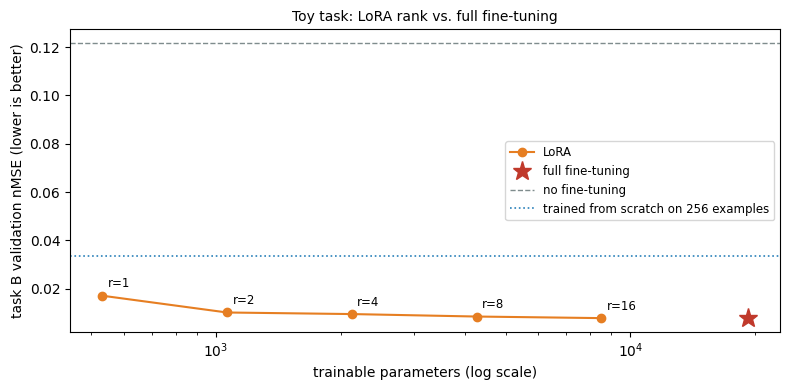

rank of the learned update in the middle layer (r = 4): 4


In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
xs = [count_params(lora_runs[r][2])[0] for r in RANKS]
ax.plot(xs, [lora_runs[r][0] for r in RANKS], "o-", color="#e67e22", label="LoRA")
for r, xv in zip(RANKS, xs):
    ax.annotate(f"r={r}", (xv, lora_runs[r][0]), textcoords="offset points", xytext=(4, 6), fontsize=8.5)
ax.plot(count_params(full_run[2])[0], full_run[0], "*", ms=14, color="#c0392b", label="full fine-tuning")
ax.axhline(no_ft, color="#7f8c8d", ls="--", lw=1, label="no fine-tuning")
ax.axhline(scratch_run[0], color="#2980b9", ls=":", lw=1.2, label="trained from scratch on 256 examples")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (log scale)"); ax.set_ylabel("task B validation nMSE (lower is better)")
ax.set_title("Toy task: LoRA rank vs. full fine-tuning", fontsize=10); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

r4 = lora_runs[4][2]                                                  # nn.Sequential; r4[2] is the middle LoRALinear
dW = (r4[2].scale * r4[2].B @ r4[2].A).detach()
print("rank of the learned update in the middle layer (r = 4):", torch.linalg.matrix_rank(dW).item())

**Reading the figure.** This is a toy model with one seed, so read the trends, not the third decimal place. The numbers below are from our run.

- **Pretraining matters.** Training from scratch on the 256 examples reached nMSE 0.034, while even LoRA with `r = 1` (532 trainable parameters) reached 0.017. The examples are too few to learn the task alone, but enough to *adapt* a model that already solves a related task.
- **The curve flattens quickly.** `r = 2` and `r = 4` reached 0.010, and `r = 8` matched full fine-tuning (0.008) with 4,256 trainable parameters instead of 19,204. Higher ranks added parameters without improving the score. 
- **Learning rate:** the best rate was 1e-3 for full fine-tuning and for LoRA with `r ≥ 2`, so the "larger learning rate" rule of thumb did not hold here. 
- **The learned update has rank at most `r`** (the printed rank is 4). That is guaranteed by the factorization, whatever the data.
- Hu et al. (2021) report the same pattern on GPT-3 175B: adapting only the query and value projections with ranks as small as 1 performed comparably to much higher ranks on their benchmarks. Real tasks that differ more from pretraining, such as a new language or domain, can need larger ranks or more target modules.

## 7. Merging and swapping adapters

### Merging: no extra cost at inference

After training, `W₀ + (α/r)·BA` is just another `d × k` matrix. Adding it into the weight once gives a model with **exactly the original architecture**: the same number of parameters, the same speed, and no extra layers. This is LoRA's advantage over adapters and prompt tuning.

In [30]:
model = lora_runs[4][2]
before = model(xBv)
for m in model.modules():
    if isinstance(m, LoRALinear):
        m.merge()
after = model(xBv)
print("max |difference| after merging:", (after - before).abs().max().item())
assert torch.allclose(after, before, atol=1e-5)
for m in model.modules():
    if isinstance(m, LoRALinear):
        m.unmerge()                                                     # back to base + separate adapter

max |difference| after merging: 4.76837158203125e-07


The difference is at the level of floating-point rounding: merging changes how the result is computed, not the result.

### Swapping: one base model, many small adapters

If the adapters are **not** merged, one frozen base model can serve several tasks. Each task only needs its own `A` and `B` matrices. We train a second adapter on another related task C, then load each adapter onto the same base.

In [31]:
# An adapter is just the A and B matrices of every LoRALinear layer; this pulls them out of a model
def lora_state(model):
    # Keep only entries whose names end in ".A" or ".B" (e.g. "2.A"), skipping the frozen "base" weights;
    # clone() makes an independent copy, so later changes to the model cannot alter the saved adapter
    return {k: v.clone() for k, v in model.state_dict().items() if k.endswith((".A", ".B"))}


# How many megabytes a set of tensors takes when saved to disk with torch.save
def size_mb(state):
    # Save into an in-memory buffer instead of a file, then read off its size in bytes (1 MB = 1e6 bytes)
    buffer = io.BytesIO(); torch.save(state, buffer); return buffer.getbuffer().nbytes / 1e6


# Task C: a second perturbation of the pretraining teacher A (a different seed from task B), so it is related to A but differs from B
teacher_C = make_teacher(base=teacher_A, seed=2)
# As for task B: only 256 training examples, plus 1,000 held-out examples for validation
xC, yC = make_data(teacher_C, 256, seed=30); xCv, yCv = make_data(teacher_C, 1000, seed=31)

# Adapter B: the A and B matrices of the r = 4 model trained on task B in Section 6
adapter_B = lora_state(lora_runs[4][2])
# Train a new r = 4 adapter (alpha = 2r = 8, as in Section 6) on task C, starting from a fresh copy of the same base;
# it reuses the learning rate that worked best for r = 4 on task B rather than tuning it again
model_C = train(add_lora(copy.deepcopy(base), r=4, alpha=8), xC, yC, steps=FT_STEPS, lr=lora_runs[4][1])
# Adapter C: the A and B matrices of that model
adapter_C = lora_state(model_C)

# One copy of the frozen base, wrapped with r = 4 LoRA layers; its own freshly initialized A and B get overwritten below
shared = add_lora(copy.deepcopy(base), r=4, alpha=8)
# Header row of the results table
print(f"{'':<12}{'task B nMSE':>12}{'task C nMSE':>12}")
# Plug each adapter into the same base in turn and evaluate it on both tasks
for name, adapter in [("adapter B", adapter_B), ("adapter C", adapter_C)]:
    # Replace only A and B; strict=False allows the missing base weights in the dict, so the base stays untouched
    shared.load_state_dict(adapter, strict=False)
    # Validation nMSE on task B and on task C with this adapter (lower is better)
    print(f"{name:<12}{nmse(shared, xBv, yBv):>12.3f}{nmse(shared, xCv, yCv):>12.3f}")
# Compare what must be stored: the whole base model versus one adapter
print(f"\nsize of the full model: {size_mb(base.state_dict()):.3f} MB | one adapter: {size_mb(adapter_B):.3f} MB")

             task B nMSE task C nMSE
adapter B          0.010       0.386
adapter C          0.265       0.013

size of the full model: 0.080 MB | one adapter: 0.011 MB


**Reading the output**

- Each adapter does best on its **own** task: in our run, nMSE 0.010 for adapter B on task B and 0.013 for adapter C on task C. Swapping only `A` and `B` changes which task the same base model performs.
- On the *other* task, each adapter was **worse than the untouched base model** (adapter C scored 0.265 on task B, against the base model's 0.122). An adapter specializes the model; it does not add general skill. Choose the adapter that matches the task.
- In this toy, the adapter is about a tenth of the model's file size, because the model is tiny. At real scale the ratio is very different: Section 9 saves a 2.2 MB adapter for a model of about 1 GB.
- At real scale, this is how one GPU can serve many fine-tuned variants. Hu et al. (2021) report that for GPT-3 175B, a LoRA checkpoint took about 35 MB instead of 350 GB.
- **Trade-off:** an unmerged adapter costs a little extra computation per layer (the `BA` path). A merged adapter costs nothing extra, but then the model serves only that one task.

## 8. At real scale: what LoRA saves, and what it does not

LoRA is usually applied to some or all of a decoder layer's weight matrices. Hugging Face `peft` selects them by module name, which for Qwen2.5 are `q_proj`, `k_proj`, `v_proj`, `o_proj` (attention) and `gate_proj`, `up_proj`, `down_proj` (feed-forward); Section 4 lists their shapes. Two common choices:

- **`q_proj` and `v_proj` only**, the original LoRA paper's setting;
- **all linear layers**, which is often more accurate for larger changes, for example in QLoRA (Dettmers et al., 2023, next lecture).

Memory with LoRA: the frozen weights need only their 16-bit values (2 bytes per parameter). Only the small trainable set needs gradients, master copies, and Adam state (16 bytes per parameter).

model                       q,v  r=8        all linear  r=16
Qwen2.5-0.5B        540,672 (0.11%)      8,798,208 (1.78%)
Qwen2.5-1.5B      1,089,536 (0.07%)     18,464,768 (1.20%)
Qwen2.5-7B        2,523,136 (0.03%)     40,370,176 (0.53%)


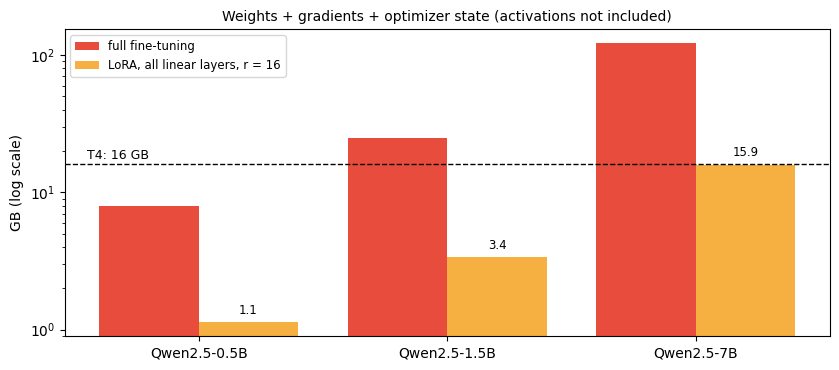

10 task-specific 7B models: 152 GB as full copies, or 15.2 GB base + 10 × 81 MB adapters


In [32]:
QV = ("q_proj", "v_proj")
ALL_LINEAR = ("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")


def lora_params(c, r, targets):
    return c["layers"] * sum(r * (i + o) for m, (i, o) in linear_shapes(c).items() if m in targets)


print(f"{'model':<14}{'q,v  r=8':>22}{'all linear  r=16':>24}")
for name, c in QWEN.items():
    n = total_params(c)
    a, b = lora_params(c, 8, QV), lora_params(c, 16, ALL_LINEAR)
    print(f"{name:<14}{a:>13,} ({a / n:.2%}){b:>15,} ({b / n:.2%})")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
xs = torch.arange(len(QWEN)).float()
full_gb = [16 * total_params(c) / GB for c in QWEN.values()]
lora_gb = [(2 * total_params(c) + 16 * lora_params(c, 16, ALL_LINEAR)) / GB for c in QWEN.values()]
ax.bar(xs - 0.2, full_gb, 0.4, color="#e74c3c", label="full fine-tuning")
ax.bar(xs + 0.2, lora_gb, 0.4, color="#f5b041", label="LoRA, all linear layers, r = 16")
for xv, v in zip(xs + 0.2, lora_gb):
    ax.text(xv, v * 1.15, f"{v:.1f}", ha="center", fontsize=8.5)
ax.axhline(16, color="k", ls="--", lw=1); ax.text(-0.45, 17.5, "T4: 16 GB", ha="left", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("GB (log scale)"); ax.set_xticks(xs); ax.set_xticklabels(list(QWEN))
ax.set_title("Weights + gradients + optimizer state (activations not included)", fontsize=10); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

c7 = QWEN["Qwen2.5-7B"]
print(f"10 task-specific 7B models: {10 * 2 * total_params(c7) / GB:.0f} GB as full copies, "
      f"or {2 * total_params(c7) / GB:.1f} GB base + 10 × {2 * lora_params(c7, 16, ALL_LINEAR) / 1e6:.0f} MB adapters")

**Reading the output**

- The trainable fraction is about 0.1% or less for `q,v`, and 0.5–2% even for all linear layers at `r = 16`. Real layers are wide, so `r · (d + k)` is tiny compared with `d · k`.
- Training memory falls to little more than the 16-bit weights. Qwen2.5-1.5B goes from about 25 GB to about 3.4 GB, and fits easily on a T4.
- **What LoRA does not save:**
  - **The frozen weights.** For the 7B model they alone take about 15 GB, which leaves almost no room for activations on a 16 GB T4.
  - **Activations.** The backward pass still runs through every layer to reach the adapters, so activation memory stays roughly what it was. Gradient checkpointing (recomputing activations instead of storing them) is the usual remedy.
- To fit a 7B model on a T4, the **frozen weights themselves** must shrink. That is **quantization**, and LoRA on a quantized base is **QLoRA**: the topic of the next lecture.

## 9. Optional: the same thing with Hugging Face `peft`

> **This section downloads a model.** Set `RUN_PEFT_DEMO = True` to run it.
> - [Qwen/Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct): about 1 GB, Apache-2.0 license.
> - Needs a **GPU (Kaggle T4)** and **internet on**. Uses `transformers` and `peft`, both preinstalled on Kaggle (otherwise `pip install transformers peft`).
> - Writes the adapter to `/kaggle/working/peft_demo_adapter/` (or `./peft_demo_adapter/` elsewhere), overwriting it on a rerun.
> - Nothing is trained. The cells repeat Section 5's checks on a real model.

`LoraConfig` describes the adapter: rank, `α`, dropout on the adapter's input, and which modules to wrap. `get_peft_model` does what our `add_lora` did: it freezes the model and wraps the matching linear layers.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package. Recent `peft` versions refuse to run when that package is older than they support, even though this notebook does not use it. The error is `ImportError: Found an incompatible version of torchao`. If you see it, uncomment and run the cell below once, then **restart the kernel** and run the notebook again. `peft` checks for `torchao` when it is first imported, so the restart is needed.

In [33]:
# Environment fix, only if get_peft_model raises "Found an incompatible version of torchao".
# Removes a package this notebook does not use; restart the kernel afterwards.
# %pip uninstall -y torchao

In [39]:
RUN_PEFT_DEMO = True          # True: download Qwen2.5-0.5B-Instruct (~1 GB) and repeat the checks on it

if RUN_PEFT_DEMO:
    from peft import LoraConfig, get_peft_model
    from transformers import AutoModelForCausalLM, AutoTokenizer

    CKPT = "Qwen/Qwen2.5-0.5B-Instruct"
    tokenizer = AutoTokenizer.from_pretrained(CKPT)
    # T4 has no bf16 support, so load in fp16. (transformers older than 4.56 call this argument torch_dtype.)
    qwen = AutoModelForCausalLM.from_pretrained(CKPT, dtype=torch.float16).to("cuda")
    print(qwen.model.layers[0].self_attn)          # note k_proj/v_proj: 896 -> 128 (grouped-query attention)

    batch = tokenizer(["Recipe: masala dosa. Ingredients:"], return_tensors="pt").to("cuda")
    with torch.no_grad():
        base_logits = qwen(**batch).logits.float()

    config = LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
    peft_model = get_peft_model(qwen, config)      # wraps qwen in place
    peft_model.print_trainable_parameters()
    n_trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
    print(f"our formula: {lora_params(QWEN['Qwen2.5-0.5B'], 8, QV):,} | peft: {n_trainable:,}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Qwen2Attention(
  (q_proj): Linear(in_features=896, out_features=896, bias=True)
  (k_proj): Linear(in_features=896, out_features=128, bias=True)
  (v_proj): Linear(in_features=896, out_features=128, bias=True)
  (o_proj): Linear(in_features=896, out_features=896, bias=False)
)
trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093
our formula: 540,672 | peft: 540,672


- In our run on a T4, `peft` reported exactly 540,672 trainable parameters, the number our formula from Section 8 predicts.
- Its "all params" figure, 494,573,440, is the base model's 494,032,768 **plus** the adapter. That is why its percentage differs slightly from the fractions in Section 8.

In [40]:
if RUN_PEFT_DEMO:
    print(peft_model.base_model.model.model.layers[0].self_attn.q_proj)   # base_layer + lora_A + lora_B

    peft_model.eval()                                                   # disables lora_dropout
    with torch.no_grad():
        lora_logits = peft_model(**batch).logits.float()
    print("max |logit difference| at initialization:", (lora_logits - base_logits).abs().max().item())

    peft_model.train()
    peft_model(**batch, labels=batch["input_ids"]).loss.backward()
    names_with_grad = [n for n, p in peft_model.named_parameters() if p.grad is not None]
    print(f"{len(names_with_grad)} tensors received gradients, all LoRA:", all("lora_" in n for n in names_with_grad))
    q0 = peft_model.base_model.model.model.layers[0].self_attn.q_proj
    print(f"layer 0 q_proj: ‖grad A‖ = {q0.lora_A['default'].weight.grad.norm():.4f}, "
          f"‖grad B‖ = {q0.lora_B['default'].weight.grad.norm():.4f}")

lora.Linear(
  (base_layer): Linear(in_features=896, out_features=896, bias=True)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.05, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=896, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=896, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)
max |logit difference| at initialization: 0.0
96 tensors received gradients, all LoRA: True
layer 0 q_proj: ‖grad A‖ = 0.0000, ‖grad B‖ = 0.1651


- The printed `q_proj` is now a `peft` LoRA layer containing the original `base_layer`, `lora_A` (896 → 8), and `lora_B` (8 → 896).
- The logit difference at initialization is exactly 0.0, because `lora_B` starts at zero, as in Section 4.
- 96 tensors receive gradients: 24 layers × 2 wrapped modules (`q_proj`, `v_proj`) × 2 matrices (`A`, `B`). All of them are LoRA tensors.
- In this first backward pass `‖grad A‖ = 0` while `‖grad B‖ > 0` (0.165 in our run): the same pattern as our hand-written gradients in Section 4.

In [41]:
if RUN_PEFT_DEMO:
    out_dir = "/kaggle/working/peft_demo_adapter" if os.path.isdir("/kaggle/working") else "peft_demo_adapter"
    peft_model.save_pretrained(out_dir)                                 # saves only the adapter
    for f in sorted(os.listdir(out_dir)):
        print(f"{f:<32}{os.path.getsize(os.path.join(out_dir, f)) / 1e6:8.2f} MB")

    merged = peft_model.merge_and_unload()                              # W0 + (alpha/r) B A, wrapper removed
    print(type(merged.model.layers[0].self_attn.q_proj).__name__)       # a plain Linear again

README.md                           0.01 MB
adapter_config.json                 0.00 MB
adapter_model.safetensors           2.18 MB
Linear


- The saved adapter is 2.18 MB (`adapter_model.safetensors` plus a small `adapter_config.json`), compared with about 1 GB for the base model. That is 540,672 parameters × 4 bytes: `peft` keeps adapter weights in fp32 even when the base model is fp16, because 16-bit adapter training can be numerically unstable (its default `autocast_adapter_dtype=True`). To use it later, load the base model and then the adapter with `PeftModel.from_pretrained(base_model, out_dir)`.
- `merge_and_unload()` is Section 7's merge: the result is an ordinary Qwen model with updated weights and no LoRA layers.

## 10. Summary

| Idea | What it means | Where we saw it |
| --- | --- | --- |
| Cost of full fine-tuning | about 16 bytes per trainable parameter, plus activations | Section 1 |
| PEFT | freeze the pretrained weights; train a small set of new or selected parameters | Section 2 |
| Low intrinsic rank | the *change* needed for a new task can be much simpler than the weights themselves | Section 3 |
| LoRA update | `ΔW = (α/r)·BA`, rank ≤ `r`, with `r·(d + k)` trainable parameters instead of `d·k` | Sections 4–5 |
| Zero-initialized `B` | training starts exactly at the pretrained model; `A` receives gradients once `B ≠ 0` | Section 4 |
| Merging | `W₀ + (α/r)·BA` gives the original architecture: no extra inference cost | Section 7 |
| Adapter swapping | one frozen base, many small task-specific adapters | Section 7 |
| What LoRA does not shrink | the frozen weights and the activations | Section 8 |

**Common misconceptions**

- *"LoRA makes the model smaller."* No. The base model is unchanged. LoRA makes **training** cheaper and **checkpoints** smaller.
- *"Rank `r` means the model can only learn `r` things."* No. Each wrapped matrix gets its own rank-`r` update, across every layer: Qwen2.5-0.5B with `q,v` adapters has 48 of them.
- *"LoRA also removes activation memory."* Mostly not. The backward pass still runs through the frozen layers.
- *"PEFT is an evaluation technique."* PEFT is a way to **adapt** a model. A LoRA model is evaluated like any fine-tuned model: against the base model and full fine-tuning, with the same prompts, data, and decoding settings.

## 11. Check your understanding

1. A weight matrix has shape 4096 × 4096. How many parameters does a LoRA adapter with `r = 16` add? What fraction of the matrix is that?
2. Why does LoRA initialize `B` to zero and `A` randomly, rather than both randomly or both to zero?
3. In the first training step, which of `A` and `B` receives a nonzero gradient? Explain with the gradient formulas.
4. What problem does the `α / r` scaling solve?
5. After `merge()`, how does the model's inference cost compare with the original model's? When would you keep adapters **unmerged**?
6. Which parts of training memory does LoRA reduce, and which does it leave unchanged?
7. Why does BitFit work poorly on Llama-style models?
8. Qwen2.5-7B needs about 15 GB for its 16-bit weights. Why does LoRA alone not make fine-tuning it on a 16 GB T4 practical?

<details>
<summary><b>Show answers</b></summary>

1. `16 × (4096 + 4096) = 131,072` parameters, which is 0.78% of the 16,777,216 in the matrix.
2. `B = 0` makes `BA = 0`, so training starts exactly from the pretrained model. A random `A` is needed so that `B` receives gradients (`∂L/∂B ∝ g(Ax)ᵀ`). If both were zero, both gradients would be zero forever. If both were random, the model would start from a randomly disturbed version of the pretrained model.
3. Only `B`. `∂L/∂B ∝ g(Ax)ᵀ` is nonzero because `A` is random, while `∂L/∂A ∝ Bᵀg xᵀ` is zero because `B = 0`. Once `B` has been updated, `A` also receives gradients.
4. It keeps the size of the update roughly the same when `r` changes, so the learning rate does not have to be retuned for each rank.
5. The same: the merged weight is an ordinary `d × k` matrix. Keep adapters unmerged to serve several tasks from one base model, or to switch them on and off.
6. It removes gradients, fp32 master copies, and optimizer state for the frozen weights (14 of the 16 bytes per parameter). It does not shrink the frozen 16-bit weights or, mostly, the activations.
7. BitFit trains only biases, and Llama-style models have essentially no bias terms, so there is almost nothing to train.
8. The frozen 16-bit weights alone take about 15 GB, leaving almost nothing for activations, the adapter's training state, and CUDA overhead. The weights themselves must shrink: quantization and QLoRA, next lecture.

</details>

## References

1. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
2. Aghajanyan, Zettlemoyer & Gupta, [Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning](https://arxiv.org/abs/2012.13255), 2020.
3. Houlsby et al., [Parameter-Efficient Transfer Learning for NLP](https://arxiv.org/abs/1902.00751), 2019. (adapters)
4. Lester, Al-Rfou & Constant, [The Power of Scale for Parameter-Efficient Prompt Tuning](https://arxiv.org/abs/2104.08691), 2021 · Li & Liang, [Prefix-Tuning: Optimizing Continuous Prompts for Generation](https://arxiv.org/abs/2101.00190), 2021.
5. Ben Zaken, Ravfogel & Goldberg, [BitFit: Simple Parameter-efficient Fine-tuning for Transformer-based Masked Language-models](https://arxiv.org/abs/2106.10199), 2021.
6. Kalajdzievski, [A Rank Stabilization Scaling Factor for Fine-Tuning with LoRA](https://arxiv.org/abs/2312.03732), 2023. (rsLoRA)
7. Rajbhandari et al., [ZeRO: Memory Optimizations Toward Training Trillion Parameter Models](https://arxiv.org/abs/1910.02054), 2019. (16 bytes per parameter)
8. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023. (next lecture)
9. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024 · [Qwen2.5-0.5B-Instruct model card](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct).
10. Hugging Face [PEFT documentation](https://huggingface.co/docs/peft) and [LoRA conceptual guide](https://huggingface.co/docs/peft/conceptual_guides/lora).